In [20]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import shutil
import random


In [21]:
import zipfile
import os

zip_path = "/content/mudra.zip"
extract_path = "/content/mudra_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

dataset_path = "/content/mudra_dataset/Bharatanatyam_Mudras"

print(os.listdir(dataset_path))

['Musti', 'Pataka', 'Simhamukha', 'Trisula', 'Sikhara']


In [39]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

dataset_path = "/content/mudra_dataset/Bharatanatyam_Mudras"

data = []

for class_name in os.listdir(dataset_path):
    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        count = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))
        ])

        data.append([class_name, count])

df = pd.DataFrame(data, columns=["Class", "Image_Count"])

print(df)
print("\nTotal images:", df["Image_Count"].sum())
print("\nMissing values:\n", df.isnull().sum())

        Class  Image_Count
0       Musti          400
1      Pataka          400
2  Simhamukha          400
3     Trisula          400
4     Sikhara          400

Total images: 2000

Missing values:
 Class          0
Image_Count    0
dtype: int64


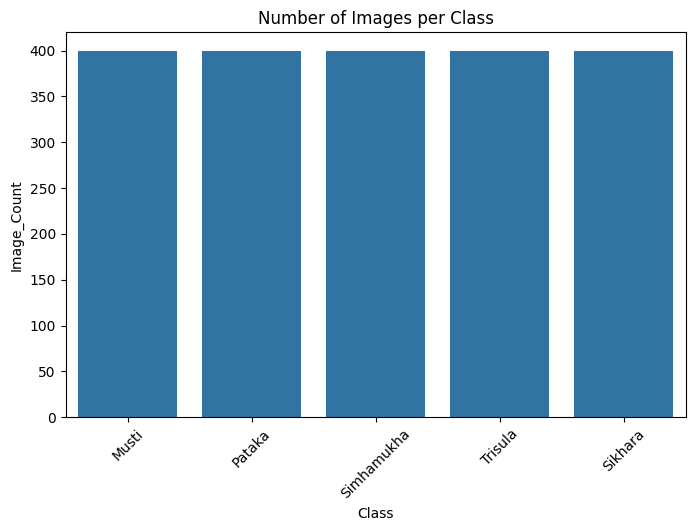

In [40]:
plt.figure(figsize=(8, 5))
import seaborn as sns
sns.barplot(data=df, x="Class", y="Image_Count")

plt.title("Number of Images per Class")
plt.xticks(rotation=45)
plt.show()

**Is the dataset balanced? How might imbalance affect learning?**

the dataset is balanced because it contains 2,000 images distributed equally among five classes: Musti, Pataka, Sikhara, Simhamukha and Trisula. Each class contains 400 images.

A balanced dataset helps the model learn from each class without one class dominating the training process. If the dataset were imbalanced, the model might become biased towards the majority class and perform poorly on minority classes. However, a balanced dataset does not guarantee good classification performance because image quality

**What image characteristics could make mudra recognition difficult?**

Several image characteristics can make mudra recognition difficult. Variations in lighting, background, hand orientation, camera angle and image quality can affect the model's ability to identify a mudra. Similar finger positions between different mudras can also cause confusion. Partially hidden fingers, blurred images and differences in hand size or distance from the camera may further reduce classification accuracy.


 **Would increasing image resolution always improve performance? Justify.**

Increasing image resolution does not always improve model performance. Higher-resolution images can preserve fine details of finger positions, which may help distinguish similar mudras. However, they require more memory, computational resources and training time. If the original images have limited detail, increasing their resolution cannot recover missing information. Therefore, the image resolution should be selected by comparing validation performance, computational cost and inference speed.


In [22]:
for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)
    print(folder, ":", len(os.listdir(folder_path)), "images")

Musti : 400 images
Pataka : 400 images
Simhamukha : 400 images
Trisula : 400 images
Sikhara : 400 images


In [23]:


random.seed(42)

source_path = "/content/mudra_dataset/Bharatanatyam_Mudras"
split_path = "/content/mudra_split"

if os.path.exists(split_path):
    shutil.rmtree(split_path)

for split in ["train", "validation", "test"]:
    os.makedirs(os.path.join(split_path, split), exist_ok=True)

for class_name in os.listdir(source_path):
    class_path = os.path.join(source_path, class_name)

    if not os.path.isdir(class_path):
        continue

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    random.shuffle(images)

    train_end = int(len(images) * 0.70)
    val_end = train_end + int(len(images) * 0.15)

    split_images = {
        "train": images[:train_end],
        "validation": images[train_end:val_end],
        "test": images[val_end:]
    }

    for split, files_list in split_images.items():
        dest = os.path.join(split_path, split, class_name)
        os.makedirs(dest, exist_ok=True)

        for image_name in files_list:
            shutil.copy2(
                os.path.join(class_path, image_name),
                os.path.join(dest, image_name)
            )

print("dataset split completed")

for split in ["train", "validation", "test"]:
    total = sum(
        len(files)
        for _, _, files in os.walk(os.path.join(split_path, split))
    )
    print(f"{split}: {total} images")

dataset split completed
train: 1400 images
validation: 300 images
test: 300 images


In [24]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/mudra_split/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/mudra_split/validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/mudra_split/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("classes:", class_names)
print("number of classes:", len(class_names))

Found 1400 files belonging to 5 classes.
Found 300 files belonging to 5 classes.
Found 300 files belonging to 5 classes.
classes: ['Musti', 'Pataka', 'Sikhara', 'Simhamukha', 'Trisula']
number of classes: 5


In [25]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [26]:
for images, labels in train_ds.take(1):
    print("image shape:", images.shape)
    print("label shape:", labels.shape)
    print("pixel range:", tf.reduce_min(images).numpy(),
          tf.reduce_max(images).numpy())
    print("sample labels:", labels[:10].numpy())

image shape: (32, 128, 128, 3)
label shape: (32,)
pixel range: 0.0 255.0
sample labels: [3 1 2 4 2 0 4 4 3 0]


**Which augmentation techniques preserve the semantic meaning of hand gestures?**

Small rotations, moderate zoom, slight translations and carefully controlled brightness adjustments can help the model generalize to different practice conditions while preserving the identity of a mudra. These transformations introduce realistic variations in image appearance without substantially changing the hand gesture. The transformations should be selected carefully to avoid cropping important fingers or changing the apparent hand configuration.


**Which augmentations could negatively impact classification accuracy, and why?**

Excessive rotation, aggressive cropping, large translations and strong distortions can remove or alter important finger-position details. Horizontal flipping may also be inappropriate if it changes the meaning or expected orientation of a gesture in the intended application. Such transformations can create unrealistic training samples, making it harder for the model to learn the correct features. Therefore, augmentation strength should be selected carefully and validated experimentally.


In [41]:
import tensorflow as tf
import pandas as pd
import time

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Rescaling, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

def build_cnn(learning_rate=0.001, dropout_rate=0.5):

    model = Sequential([
        Rescaling(1./255, input_shape=(128, 128, 3)),

        Conv2D(32, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Flatten(),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(5, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


experiments = [
    {"learning_rate": 0.001, "dropout_rate": 0.3},
    {"learning_rate": 0.0001, "dropout_rate": 0.3},
    {"learning_rate": 0.001, "dropout_rate": 0.5},
    {"learning_rate": 0.0001, "dropout_rate": 0.5}
]

results = []

for experiment in experiments:

    print("\nExperiment:", experiment)

    model_exp = build_cnn(
        learning_rate=experiment["learning_rate"],
        dropout_rate=experiment["dropout_rate"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    start_time = time.time()

    history_exp = model_exp.fit(
        train_ds,
        validation_data=val_ds,
        epochs=15,
        callbacks=[early_stop],
        verbose=1
    )

    elapsed_time = time.time() - start_time

    best_epoch = (
        history_exp.history["val_loss"].index(
            min(history_exp.history["val_loss"])
        ) + 1
    )

    best_val_accuracy = max(
        history_exp.history["val_accuracy"]
    )

    best_val_loss = min(
        history_exp.history["val_loss"]
    )

    results.append({
        "Learning Rate": experiment["learning_rate"],
        "Dropout": experiment["dropout_rate"],
        "Best Epoch": best_epoch,
        "Best Validation Accuracy": best_val_accuracy,
        "Best Validation Loss": best_val_loss,
        "Training Time (seconds)": round(elapsed_time, 2)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Best Validation Accuracy",
        ascending=False
    )
)


Experiment: {'learning_rate': 0.001, 'dropout_rate': 0.3}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 38s 732ms/step - accuracy: 0.7457 - loss: 0.7448 - val_accuracy: 0.9933 - val_loss: 0.0303
Epoch 2/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 39s 721ms/step - accuracy: 0.9979 - loss: 0.0115 - val_accuracy: 1.0000 - val_loss: 0.0058
Epoch 3/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 35s 804ms/step - accuracy: 0.9964 - loss: 0.0081 - val_accuracy: 1.0000 - val_loss: 5.8775e-05
Epoch 4/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 36s 823ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 1.2448e-05
Epoch 5/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 42s 849ms/step - accuracy: 1.0000 - loss: 2.5896e-04 - val_accuracy: 1.0000 - val_loss: 1.7648e-06
Epoch 6/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 33s 666ms/step - accuracy: 1.0000 - loss: 1.6343e-04 - val_accuracy: 1.0000 - val_loss: 2.9444e-07
Epoch 7/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 41s 661ms/step - accuracy: 1.0000 - loss: 2.8981e-04 - val_accuracy: 1.0000 - val_loss: 1.8561e-05
Epoch 8/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 37s 840ms/step - accuracy: 

KeyboardInterrupt: 

In [27]:
#model build

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Rescaling

model = Sequential([
    Rescaling(1./255, input_shape=(128, 128, 3)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(5, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,285 (12.61 MB)

 Trainable params: 3,305,285 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [28]:
#compile

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [31]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [32]:
#train the model

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 31s 672ms/step - accuracy: 0.8343 - loss: 0.4343 - val_accuracy: 1.0000 - val_loss: 3.6653e-04
Epoch 2/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 43s 721ms/step - accuracy: 0.9957 - loss: 0.0137 - val_accuracy: 1.0000 - val_loss: 4.9592e-04
Epoch 3/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 45s 806ms/step - accuracy: 0.9950 - loss: 0.0214 - val_accuracy: 1.0000 - val_loss: 5.7657e-07
Epoch 4/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 36s 690ms/step - accuracy: 0.9914 - loss: 0.0263 - val_accuracy: 1.0000 - val_loss: 1.4406e-05
Epoch 5/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 48s 856ms/step - accuracy: 0.9979 - loss: 0.0119 - val_accuracy: 1.0000 - val_loss: 1.8063e-06
Epoch 6/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 38s 788ms/step - accuracy: 0.9957 - loss: 0.0150 - val_accuracy: 1.0000 - val_loss: 5.2924e-06


In [33]:
#evaluation
test_loss, test_accuracy = model.evaluate(test_ds)

print("test Loss:", test_loss)
print("test Acc:", round(test_accuracy * 100, 2), "%")

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 161ms/step - accuracy: 1.0000 - loss: 7.9231e-07
test Loss: 7.923099474282935e-07
test Acc: 100.0 %


 E**xplain the effect of your hyperparameter choices.**

The learning rate controls how much the model's weights change during optimization. A high learning rate can speed up training but may cause unstable learning or prevent the model from reaching a good solution. A lower learning rate can provide more gradual updates but may require more training time.

The batch size determines how many training images are processed before the model updates its weights. A smaller batch size uses less memory and produces more frequent updates, while a larger batch size can improve computational efficiency but requires more memory.

The final hyperparameter configuration should be selected based on validation performance and computational cost.


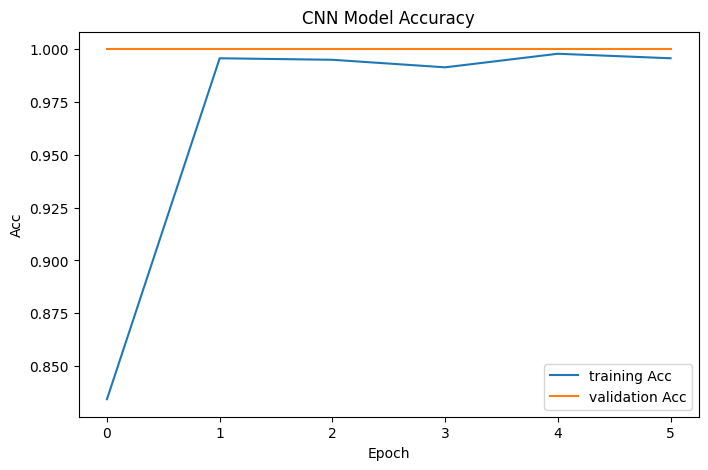

In [34]:
#graph
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='training Acc')
plt.plot(history.history['val_accuracy'], label='validation Acc')
plt.xlabel('Epoch')
plt.ylabel('Acc')
plt.title('CNN Model Accuracy')
plt.legend()
plt.show()

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 186ms/step
              precision    recall  f1-score   support

       Musti       1.00      1.00      1.00        60
      Pataka       1.00      1.00      1.00        60
     Sikhara       1.00      1.00      1.00        60
  Simhamukha       1.00      1.00      1.00        60
     Trisula       1.00      1.00      1.00        60

    accuracy                           1.00       300
   macro avg       1.00      1.00      1.00       300
weighted avg       1.00      1.00      1.00       300



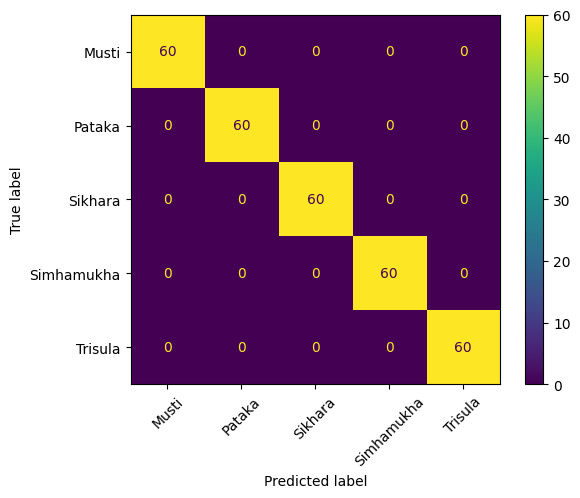

In [35]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

y_true = np.concatenate([labels.numpy() for images, labels in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(xticks_rotation=45)
plt.show()

**Suggest one data-centric and one model-centric improvement.**

Data-centric improvement: Collect additional diverse images for classes that are frequently confused. Include variations in lighting, camera angle, background and hand position while ensuring that the labels are correct.

Model-centric improvement: Experiment with a different CNN architecture or adjust the learning rate and regularization. Compare the resulting validation performance to determine whether the changes improve generalization.


In [36]:
model.save("/content/mudra_cnn.keras")
print("Model saved successfully!")

Model saved successfully!


**Why is displaying prediction confidence important for end users?**

Displaying prediction confidence helps users understand the model's estimated certainty about its prediction. It allows users to identify predictions that may require further checking, particularly when two mudras look similar. However, confidence is not a guarantee of correctness, and an uncalibrated model can produce high confidence even for incorrect predictions.


 **What additional feature would make this application more useful for dance learners?**

A useful additional feature would be a visual comparison between the uploaded hand gesture and a reference image of the predicted mudra. This would help learners compare finger positions and hand orientation. In the future, the application could also provide feedback on gesture alignment, provided that the feedback is supported by a suitably evaluated pose-estimation or hand-landmark model.


In [29]:
test_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [30]:
val_ds

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [43]:
#bonas task


import tensorflow as tf
import pandas as pd
import time

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Rescaling, Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

def build_cnn(learning_rate=0.001, dropout_rate=0.5):

    model = Sequential([
        Rescaling(1./255, input_shape=(128, 128, 3)),

        Conv2D(32, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Conv2D(64, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Conv2D(128, (3, 3), activation="relu"),
        MaxPooling2D((2, 2)),

        Flatten(),
        Dense(128, activation="relu"),
        Dropout(dropout_rate),
        Dense(5, activation="softmax")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


experiments = [
    {"learning_rate": 0.001, "dropout_rate": 0.3},
    {"learning_rate": 0.0001, "dropout_rate": 0.3},
    {"learning_rate": 0.001, "dropout_rate": 0.5},
    {"learning_rate": 0.0001, "dropout_rate": 0.5}
]

results = []

for experiment in experiments:

    print("\nExperiment:", experiment)

    model_exp = build_cnn(
        learning_rate=experiment["learning_rate"],
        dropout_rate=experiment["dropout_rate"]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    start_time = time.time()

    history_exp = model_exp.fit(
        train_ds,
        validation_data=val_ds,
        epochs=5,
        callbacks=[early_stop],
        verbose=1
    )

    elapsed_time = time.time() - start_time

    best_epoch = (
        history_exp.history["val_loss"].index(
            min(history_exp.history["val_loss"])
        ) + 1
    )

    best_val_accuracy = max(
        history_exp.history["val_accuracy"]
    )

    best_val_loss = min(
        history_exp.history["val_loss"]
    )

    results.append({
        "Learning Rate": experiment["learning_rate"],
        "Dropout": experiment["dropout_rate"],
        "Best Epoch": best_epoch,
        "Best Validation Accuracy": best_val_accuracy,
        "Best Validation Loss": best_val_loss,
        "Training Time (seconds)": round(elapsed_time, 2)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        "Best Validation Accuracy",
        ascending=False
    )
)


Experiment: {'learning_rate': 0.001, 'dropout_rate': 0.3}
Epoch 1/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 31s 643ms/step - accuracy: 0.8650 - loss: 0.3902 - val_accuracy: 1.0000 - val_loss: 0.0027
Epoch 2/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 41s 663ms/step - accuracy: 0.9986 - loss: 0.0052 - val_accuracy: 1.0000 - val_loss: 1.9743e-05
Epoch 3/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 40s 641ms/step - accuracy: 0.9986 - loss: 0.0050 - val_accuracy: 1.0000 - val_loss: 0.0015
Epoch 4/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 29s 651ms/step - accuracy: 0.9964 - loss: 0.0201 - val_accuracy: 1.0000 - val_loss: 1.9591e-05
Epoch 5/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 29s 659ms/step - accuracy: 0.9993 - loss: 0.0018 - val_accuracy: 1.0000 - val_loss: 1.1183e-04

Experiment: {'learning_rate': 0.0001, 'dropout_rate': 0.3}
Epoch 1/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 30s 662ms/step - accuracy: 0.6100 - loss: 1.2678 - val_accuracy: 0.9900 - val_loss: 0.5339
Epoch 2/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 42s 679ms/step - accuracy: 0.9764 - loss: 0.1894 - val_accuracy:

,Learning Rate,Dropout,Best Epoch,Best Validation Accuracy,Best Validation Loss,Training Time (seconds)
0,0.0010,0.3,4,1.0,1.959141e-05,170.02
1,0.0001,0.3,5,1.0,1.339477e-03,173.04
2,0.0010,0.5,5,1.0,4.509998e-07,183.66
3,0.0001,0.5,5,1.0,3.342721e-04,182.36


In [45]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

base_model.trainable = False

inputs = Input(shape=(128, 128, 3))

x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)

outputs = Dense(5, activation="softmax")(x)

mobilenet_model = Model(inputs, outputs)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [48]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import time

# Map MobileNetV2 preprocessing to our datasets
train_mobilenet = train_ds.map(lambda x, y: (preprocess_input(x), y))
val_mobilenet = val_ds.map(lambda x, y: (preprocess_input(x), y))

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

start_time = time.time()

mobilenet_history = mobilenet_model.fit(
    train_mobilenet,
    validation_data=val_mobilenet,
    epochs=4,
    callbacks=[early_stop]
)

mobilenet_training_time = time.time() - start_time

print(
    "MobileNetV2 training time:",
    round(mobilenet_training_time, 2),
    "seconds"
)

Epoch 1/4
44/44 ━━━━━━━━━━━━━━━━━━━━ 18s 390ms/step - accuracy: 0.9950 - loss: 0.0283 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 2/4
44/44 ━━━━━━━━━━━━━━━━━━━━ 13s 291ms/step - accuracy: 1.0000 - loss: 0.0052 - val_accuracy: 1.0000 - val_loss: 5.9541e-04
Epoch 3/4
44/44 ━━━━━━━━━━━━━━━━━━━━ 13s 284ms/step - accuracy: 1.0000 - loss: 0.0026 - val_accuracy: 1.0000 - val_loss: 3.4556e-04
Epoch 4/4
44/44 ━━━━━━━━━━━━━━━━━━━━ 13s 287ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 2.1028e-04
MobileNetV2 training time: 55.73 seconds


In [50]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Map MobileNetV2 preprocessing to the test dataset
test_mobilenet = test_ds.map(lambda x, y: (preprocess_input(x), y))

test_loss, test_accuracy = mobilenet_model.evaluate(
    test_mobilenet
)

print("MobileNetV2 Test Loss:", test_loss)
print(
    "MobileNetV2 Test Accuracy:",
    round(test_accuracy * 100, 2),
    "%"
)

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 206ms/step - accuracy: 1.0000 - loss: 2.2520e-04
MobileNetV2 Test Loss: 0.00022519611229654402
MobileNetV2 Test Accuracy: 100.0 %
